# AI 1 · Random Forest: classic machine learning
**We train it ourselves:** many decision trees, each learns *if-then rules* from the data.
No gradient descent, the trees learn by **splitting** the data.

**The task (the same in all four notebooks):** predict tomorrow's Apple (AAPL) closing price.
We test on the **last 60 trading days**, and the model never sees them during training.

**Baseline to beat:** "tomorrow = today". If a model cannot beat this, it has learned nothing useful.

In [2]:
import pandas as pd

prices = pd.read_parquet("../lecture03_datascience/sample/prices_sample.parquet")
aapl = prices[prices["symbol"] == "AAPL"].set_index("date")["close"]
aapl.tail()

date
2025-02-10    227.65
2025-02-11    232.62
2025-02-12    236.87
2025-02-13    241.53
2025-02-14    244.60
Name: close, dtype: float64

In [8]:
aapl.info()


<class 'pandas.Series'>
DatetimeIndex: 1257 entries, 2020-02-18 to 2025-02-14
Series name: close
Non-Null Count  Dtype  
--------------  -----  
1257 non-null   float64
dtypes: float64(1)
memory usage: 19.6 KB


## Features: what the model sees

In [12]:
# Daily return in percent: +1.0 means the price rose by 1 % since yesterday
ret = aapl.pct_change() * 100

# Input X: the returns of the last 10 days (lag0 = today, lag9 = 9 days ago)
X = pd.concat({f"lag{i}": ret.shift(i) for i in range(10)}, axis=1)

# Target y: tomorrow's return
y = ret.shift(-1).rename("target")

data = pd.concat([X, y], axis=1).dropna()
data.tail(3).round(2)

,lag0,lag1,lag2,lag3,lag4,lag5,lag6,lag7,lag8,lag9,target
date,,,,,,,,,,,
2025-02-11,2.18,0.12,-2.40,0.32,-0.14,2.10,-3.39,-0.67,-0.74,0.46,1.83
2025-02-12,1.83,2.18,0.12,-2.40,0.32,-0.14,2.10,-3.39,-0.67,-0.74,1.97
2025-02-13,1.97,1.83,2.18,0.12,-2.40,0.32,-0.14,2.10,-3.39,-0.67,1.27


In [13]:
ret.info()

<class 'pandas.Series'>
DatetimeIndex: 1257 entries, 2020-02-18 to 2025-02-14
Series name: close
Non-Null Count  Dtype  
--------------  -----  
1256 non-null   float64
dtypes: float64(1)
memory usage: 19.6 KB


## Train / test split
The same `train_test_split` as for Auto MPG, with one important difference: **`shuffle=False`**.
Time series must not be shuffled. Otherwise the model trains on days *after* the test days and peeks into the future.
```
shuffle=True  (Auto MPG):  train test train train test train ...   random rows
shuffle=False (stocks)  :  train train train ... train | test test  last 60 days
```

In [14]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(data, test_size=60, shuffle=False)
print("train:", train.index.min().date(), "to", train.index.max().date(), f"({len(train)} days)")
print("test :", test.index.min().date(), "to", test.index.max().date(), f"({len(test)} days)")

train: 2020-03-03 to 2024-11-14 (1186 days)
test : 2024-11-15 to 2025-02-13 (60 days)


## Train: `fit` builds 200 trees

In [15]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(n_estimators=200, min_samples_leaf=20, random_state=42)
model.fit(train.drop(columns="target"), train["target"])

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsampl

## Predict the 60 test days

In [16]:
pred = model.predict(test.drop(columns="target"))
MODEL_NAME = "Random Forest"
pred[:5].round(3)   # predicted returns in % for the first 5 test days

array([-0.212,  0.077,  0.345,  0.248,  0.109])

## Evaluate: better than 'tomorrow = today'?

In [6]:
from sklearn.metrics import mean_absolute_error

today = aapl.loc[test.index]                      # today's price
true_price = aapl.shift(-1).loc[test.index]       # tomorrow's price (the truth)
model_price = today * (1 + pred / 100)            # return -> price

print(f"MAE baseline 'tomorrow = today': {mean_absolute_error(true_price, today):.2f} $")
print(f"MAE {MODEL_NAME:<27}: {mean_absolute_error(true_price, model_price):.2f} $")

MAE baseline 'tomorrow = today': 2.68 $
MAE Random Forest              : 2.54 $


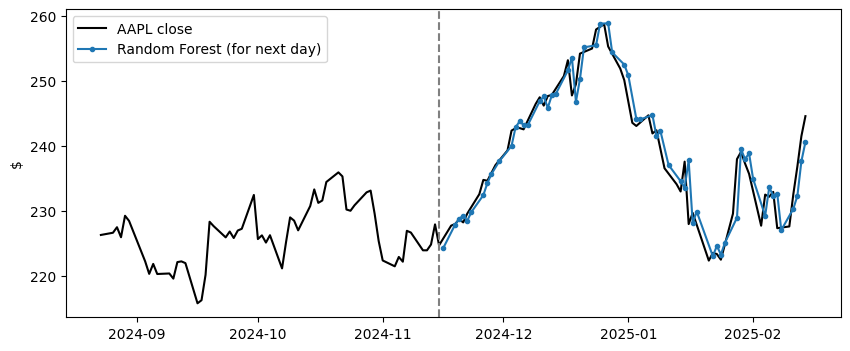

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(aapl.iloc[-120:], color="black", label="AAPL close")
ax.plot(test.index + pd.Timedelta(days=1), model_price, "o-", ms=3, label=MODEL_NAME + " (for next day)")
ax.axvline(test.index[0], color="gray", ls="--")
ax.set_ylabel("$")
ax.legend();

## Would we have made money?
Simple rule with **1 share**: if the model says "up", buy today at the close and sell tomorrow at the close.
If it says "down", do nothing. Compare with **buy & hold**: buy once and keep the share for all 60 days.

In [8]:
import numpy as np

def trading_days(today, tomorrow, pred):
    days = pd.DataFrame({"today $": today.values, "tomorrow $": tomorrow.values}, index=today.index)
    days["model says"] = np.where(pred > 0, "up -> buy", "down -> wait")
    days["profit $"] = np.where(pred > 0, days["tomorrow $"] - days["today $"], 0.0)
    days["running total $"] = days["profit $"].cumsum()
    return days.round(2)


def trading_summary(days):
    bought = days[days["model says"] == "up -> buy"]
    return pd.DataFrame({
        "days bought": [len(bought)],
        "won": [(bought["profit $"] > 0).sum()],
        "lost": [(bought["profit $"] < 0).sum()],
        "model profit $": [days["profit $"].sum()],
        "buy & hold profit $": [(days["tomorrow $"] - days["today $"]).sum()],
    }).round(2)


days = trading_days(today, true_price, pred)
days.head(8)   # the first 8 test days, one row per day

,today $,tomorrow $,model says,profit $,running total $
date,,,,,
2024-11-15,224.75,227.77,down -> wait,0.00,0.00
2024-11-18,227.77,228.03,up -> buy,0.26,0.26
2024-11-19,228.03,228.75,up -> buy,0.72,0.98
2024-11-20,228.75,228.27,up -> buy,-0.48,0.50
2024-11-21,228.27,229.62,up -> buy,1.35,1.85
2024-11-22,229.62,232.61,up -> buy,2.99,4.84
2024-11-25,232.61,234.80,down -> wait,0.00,4.84
2024-11-26,234.80,234.67,down -> wait,0.00,4.84


In [9]:
trading_summary(days)

,days bought,won,lost,model profit $,buy & hold profit $
0,44,28,16,20.52,19.85


## Check: does the AAPL model also work on other stocks?
If the forest had learned a real pattern of "how stocks move", it should also help on Microsoft, Amazon and Google.
We build the same features for each stock and use the **AAPL model unchanged**: only `predict`, **no `fit`**.

The grey line is the baseline "tomorrow = today", i.e. yesterday's price.

In [10]:
def apply_aapl_model(symbol):
    close = prices[prices["symbol"] == symbol].set_index("date")["close"]

    # same features as for AAPL
    r = close.pct_change() * 100
    X_s = pd.concat({f"lag{i}": r.shift(i) for i in range(10)}, axis=1)
    data_s = pd.concat([X_s, r.shift(-1).rename("target")], axis=1).dropna()
    _, test_s = train_test_split(data_s, test_size=60, shuffle=False)   # only the last 60 days, the rest is thrown away

    # NO fit here: the AAPL model is only applied
    pred_s = model.predict(test_s.drop(columns="target"))
    today_s = close.loc[test_s.index]
    true_s = close.shift(-1).loc[test_s.index]
    model_s = today_s * (1 + pred_s / 100)

    print(f"{symbol:<6} MAE baseline 'tomorrow = today': {mean_absolute_error(true_s, today_s):.2f} $")
    print(f"{symbol:<6} MAE AAPL forest                : {mean_absolute_error(true_s, model_s):.2f} $")

    next_day = test_s.index + pd.Timedelta(days=1)
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(close.iloc[-120:], color="black", label=f"{symbol} close")
    ax.plot(next_day, today_s, color="gray", lw=3, alpha=0.6, label="baseline: tomorrow = today")
    ax.plot(next_day, model_s, "o-", ms=3, color="C3", label="AAPL forest (for next day)")
    ax.axvline(test_s.index[0], color="gray", ls="--")
    ax.set_title(f"AAPL model applied to {symbol} (never trained on {symbol})")
    ax.set_ylabel("$")
    ax.legend()
    plt.show()
    display(trading_summary(trading_days(today_s, true_s, pred_s)))

MSFT   MAE baseline 'tomorrow = today': 4.25 $
MSFT   MAE AAPL forest                : 4.49 $


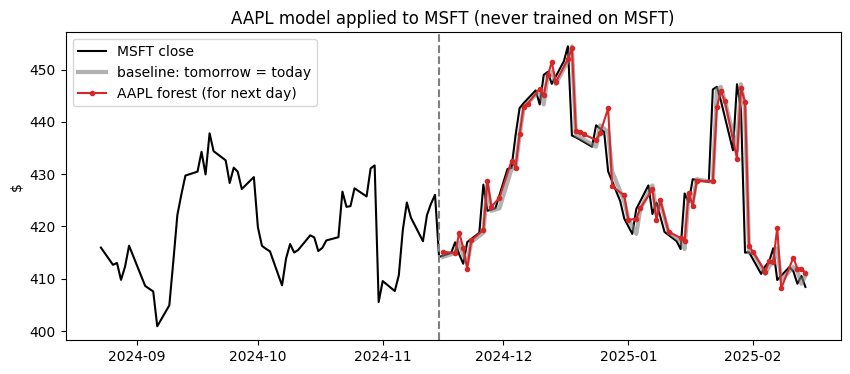

,days bought,won,lost,model profit $,buy & hold profit $
0,40,21,19,11.99,-5.74


In [11]:
apply_aapl_model("MSFT")

AMZN   MAE baseline 'tomorrow = today': 2.96 $
AMZN   MAE AAPL forest                : 2.90 $


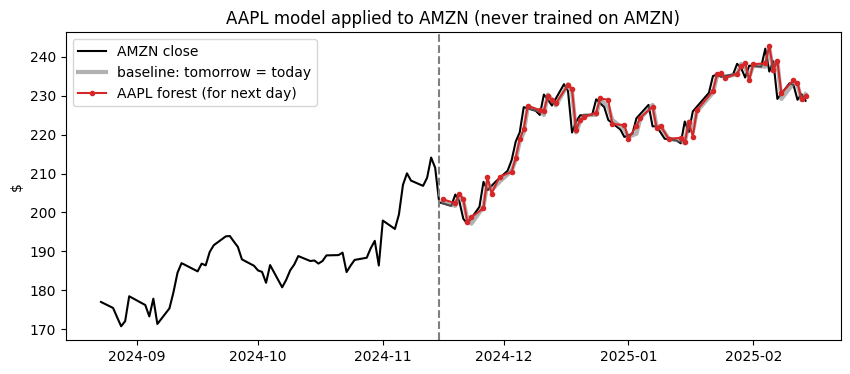

,days bought,won,lost,model profit $,buy & hold profit $
0,41,22,19,24.63,26.07


In [12]:
apply_aapl_model("AMZN")

GOOGL  MAE baseline 'tomorrow = today': 2.97 $
GOOGL  MAE AAPL forest                : 2.74 $


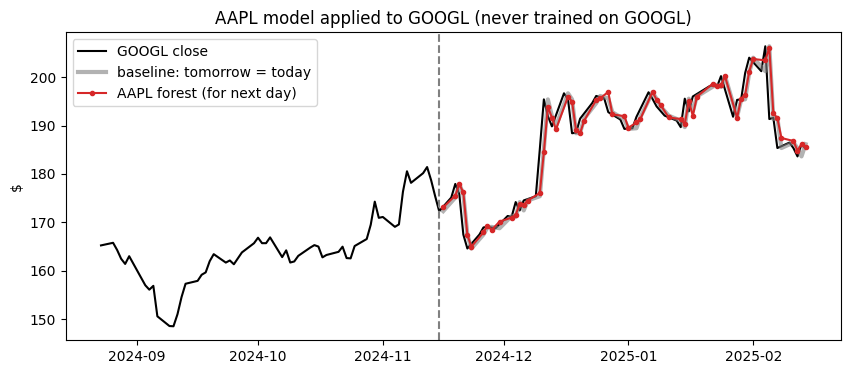

,days bought,won,lost,model profit $,buy & hold profit $
0,30,23,7,38.94,12.94


In [13]:
apply_aapl_model("GOOGL")

**Intel (INTC)** for contrast: a stock that **fell** about 60 % in 5 years. The rule 'model says up → buy' cannot ride an upward trend here.

INTC   MAE baseline 'tomorrow = today': 0.47 $
INTC   MAE AAPL forest                : 0.51 $


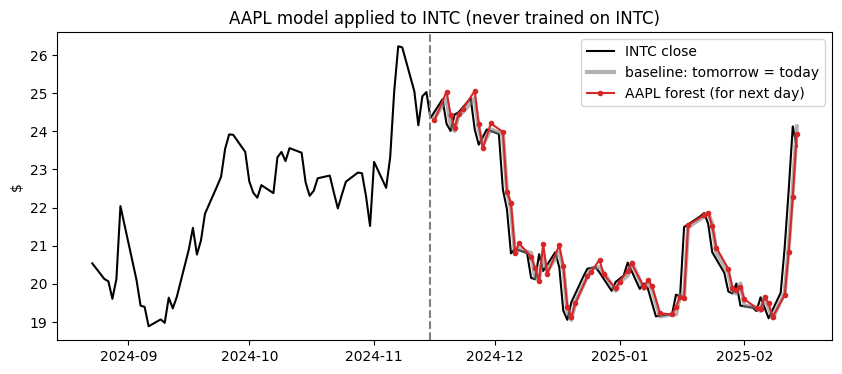

,days bought,won,lost,model profit $,buy & hold profit $
0,40,17,22,-5.1,-0.75


In [14]:
apply_aapl_model("INTC")

Red lies almost exactly on grey: the model hardly changes yesterday's price.
Red looks close to black only because one day's move (~1 %) is small compared to the y-axis.

## Takeaway
- Training took about one second on a laptop and needed **no GPU**.
- Results on the same 60 test days (MAE, lower is better):

| stock | trained on it? | MAE baseline | MAE AAPL forest | profit forest (1 share) | profit buy & hold |
|---|---|---|---|---|---|
| AAPL | yes | 2.68 $ | 2.54 $ | +20.52 $ | +19.85 $ |
| MSFT | no | 4.25 $ | 4.49 $ (worse) | +11.99 $ | −5.74 $ |
| AMZN | no | 2.96 $ | 2.90 $ | +24.63 $ | +26.07 $ |
| GOOGL | no | 2.97 $ | 2.74 $ | +38.94 $ | +12.94 $ |
| INTC | no | 0.47 $ | 0.51 $ (worse) | −5.10 $ | −0.75 $ |

- AAPL, AMZN and GOOGL rose during the test period. A model that mostly says "up" looks good there. On **Intel**, a falling stock, the same rule loses money: 22 of 40 trades lost.

- MAE and profit measure different things: MAE asks "how many $ off?", profit only asks "was the **direction** right on the days we bought?". On MSFT the MAE is worse, but the trading rule still made money.
- No trading fees and no taxes included. With fees for ~40 trades per stock, a large part of the profit would be gone.

- Mixed picture: three times a little better, once worse. The forest only shifts yesterday's price by ±0.1 … 1 %, so red and grey lie almost on top of each other.
- 60 days per stock is a small test, so such differences can be **luck**. Same lesson as Session 03: **daily returns are close to unpredictable.**
- Rule: **one good test result on one series proves nothing.** Test on other series and other periods.